# 04 Base v2 e histogramas sobrepostos de Data Drift

Criamos `data/processed/credit_scoring_v2.csv` a partir da base preparada
`credit_scoring.csv`: os mesmos **20.000 registros e dez features**, com renda
30% menor e crédito 40% maior. A base original permanece preservada.

Execute o notebook **02** antes deste, no mesmo ambiente. O notebook 03 não é
um pré-requisito. Este notebook tem kernel independente e utiliza os componentes
do `ml_prep_kit` para geração, validação, gráficos, monitoramento e MLflow.

A v2 é uma **simulação de mudança de perfil das entradas**, não uma nova coleta
real. Os rótulos e os IDs são preservados. Ela não demonstra Concept Drift nem
comprova que o desempenho necessariamente piorou. Não há treinamento aqui.


## 1 Carregar a base original e o experimento

A referência estatística continua sendo o treino do notebook 02. Embora o CSV v2
contenha a versão alterada de toda a amostra, somente os **4.000 IDs reservados
para produção** serão usados para inferência e detecção frente ao treino.
As versões completas serão usadas apenas na comparação visual pareada.


In [1]:
import sys
from datetime import UTC, datetime
from pathlib import Path

from IPython.display import Markdown, display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

from ml_prep_kit import (
    CSVDataLoader,
    DataValidator,
    DriftMonitor,
    ExperimentTracker,
    HomeCreditData,
    ModelPredictor,
    VisualizationReporter,
)

/opt/venv/lib/python3.12/site-packages/evidently/descriptors/text_match.py:140: SyntaxWarning: invalid escape sequence '\d'
  TextMatch(text_column="description", match_items=r"\b\d{3}-\d{3}-\d{4}\b", match_type="regex")


/opt/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
processed_path = project_root / "data/processed"
preparation = HomeCreditData()
validator = DataValidator()
reporter = VisualizationReporter()
loader = CSVDataLoader(processed_path)
experiment = preparation.load_experiment(processed_path)
partitions = experiment["partitions"]
version_one = preparation.contract.validate(
    loader.load({"v1": "credit_scoring.csv"})["v1"], lazy=True
)
reference = partitions["treino"]
threshold = experiment["threshold"]
predictor = ModelPredictor.from_mlflow(
    experiment["model_uri"], tracking_uri=experiment["tracking_uri"]
)

## 2 Criar e persistir a segunda versão

| Campo | Mudança aplicada | Expectativa visual |
| --- | --- | --- |
| `AMT_INCOME_TOTAL` | Multiplicar por 0,70 | Distribuição deslocada para a esquerda |
| `AMT_CREDIT` | Multiplicar por 1,40 | Distribuição deslocada para a direita |
| `AGE_YEARS` | Preservar | Sobreposição completa entre as versões pareadas |
| Demais features, ID e `TARGET` | Preservar | Isolar as duas intervenções |

Os fatores são fixos e a geração é determinística: reexecutar parte sempre da
v1, sem acumular alterações sobre a v2. O contrato Pandera valida a origem e o
resultado. Uma distribuição diferente pode continuar respeitando todas as
regras de qualidade. Os CSVs permanecem fora do Git.


In [3]:
income_factor = 0.70
credit_factor = 1.40
version_two_path = processed_path / "credit_scoring_v2.csv"
_ = preparation.create_drift_version(
    version_one,
    income_factor=income_factor,
    credit_factor=credit_factor,
    output_path=version_two_path,
)
version_two = preparation.contract.validate(
    loader.load({"v2": version_two_path.name})["v2"], lazy=True
)
display(validator.summarize({"base_v1": version_one, "base_v2": version_two}))
display(validator.compare_targets({"v1": version_one, "v2": version_two}, "TARGET"))
print(f"Base v2 salva e relida: {version_two_path.relative_to(project_root)}")

,dataset,rows,columns,memory_mb
0,base_v1,20000,12,5.185859
1,base_v2,20000,12,5.185859


,dataset,target,count,percent
0,v1,0,18385,91.925
1,v1,1,1615,8.075
2,v2,0,18385,91.925
3,v2,1,1615,8.075


Base v2 salva e relida: data/processed/credit_scoring_v2.csv


## 3 Sobrepor os histogramas das versões completas

Azul representa a v1 e laranja a v2. Cada comparação utiliza os **mesmos
intervalos** para as duas bases. O eixo vertical mostra o percentual de registros
válidos de cada base; cada distribuição soma 100%. Nulos são informados na
legenda e excluídos somente da visualização.

Renda e crédito usam escala logarítmica para mostrar também a região central,
sem cortar os valores extremos. A escala não altera os dados usados no modelo
ou nos testes. Idade permanece em escala linear.


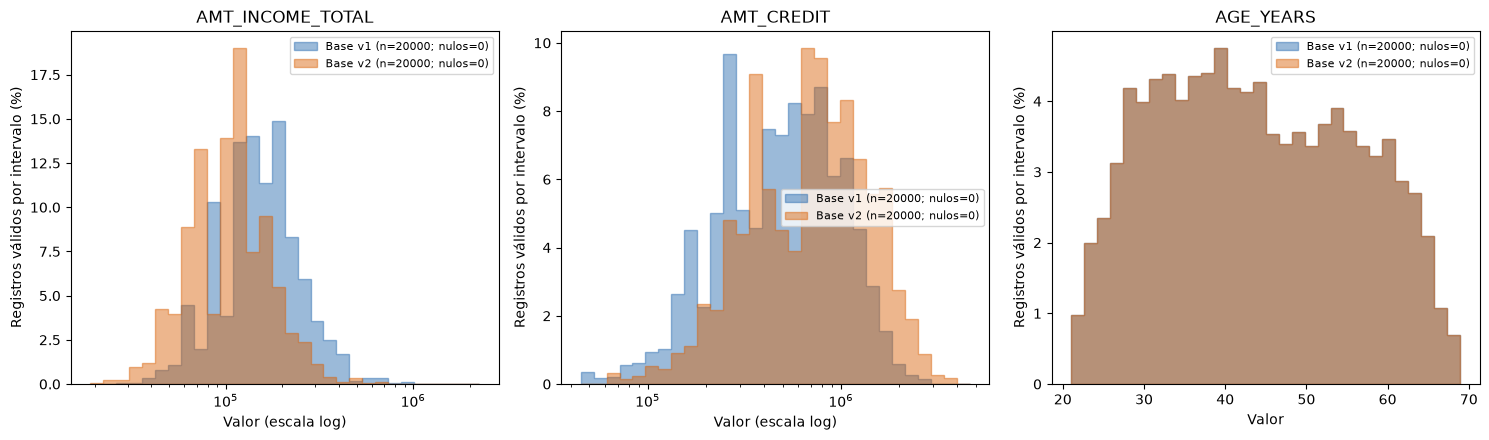

In [4]:
comparison_columns = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AGE_YEARS"]
log_columns = ["AMT_INCOME_TOTAL", "AMT_CREDIT"]
figures = {
    "v1_v2_histogramas": reporter.plot_overlaid_histograms(
        version_one,
        version_two,
        columns=comparison_columns,
        log_columns=log_columns,
        labels=("Base v1", "Base v2"),
    )
}

A renda menor desloca sua massa para valores inferiores; o crédito maior
faz o movimento oposto. A sobreposição da idade é um controle: seus valores
são idênticos nos mesmos registros. Uma das cores pode encobrir a outra nessa
comparação. As tabelas abaixo permitem conferir as mudanças de mediana e
percentis, sem depender apenas da aparência do gráfico.


In [5]:
for name, frame in {"Base v1": version_one, "Base v2": version_two}.items():
    display(Markdown(f"**{name} — estatísticas das variáveis comparadas**"))
    display(validator.describe_numeric(frame, comparison_columns))

**Base v1 — estatísticas das variáveis comparadas**

,count,mean,std,min,1%,50%,95%,99%,max
AMT_INCOME_TOTAL,20000.0,168052.175561,95258.001945,27000.000000,45000.000000,144000.000000,3.375000e+05,4.950000e+05,2.250000e+06
AMT_CREDIT,20000.0,599871.700800,404098.659443,45000.000000,76410.000000,513531.000000,1.350000e+06,1.831898e+06,3.312162e+06
AGE_YEARS,20000.0,43.745993,11.994509,21.026694,22.655715,42.945927,6.343053e+01,6.674352e+01,6.893908e+01


**Base v2 — estatísticas das variáveis comparadas**

,count,mean,std,min,1%,50%,95%,99%,max
AMT_INCOME_TOTAL,20000.0,117636.522893,66680.601361,18900.000000,31500.000000,100800.000000,2.362500e+05,3.465000e+05,1.575000e+06
AMT_CREDIT,20000.0,839820.381120,565738.123220,63000.000000,106974.000000,718943.400000,1.890000e+06,2.564657e+06,4.637027e+06
AGE_YEARS,20000.0,43.745993,11.994509,21.026694,22.655715,42.945927,6.343053e+01,6.674352e+01,6.893908e+01


## 4 Separar a produção e comparar com a referência do treino

Os histogramas anteriores isolam uma intervenção nos mesmos registros. Para
os testes estatísticos e para o modelo, usamos conjuntos com **IDs distintos**:
12.000 registros de referência e 4.000 de produção. Não usamos o CSV v2 inteiro
como produção, pois ele também contém IDs das partições de desenvolvimento.

A idade pode apresentar pequenas diferenças visuais nesta comparação por causa
da amostragem. Isso é diferente de uma alteração proposital da variável.


,dataset,rows,columns,memory_mb
0,treino_v1,12000,12,3.202961
1,producao_v1,4000,12,1.067339
2,producao_v2,4000,12,1.067339


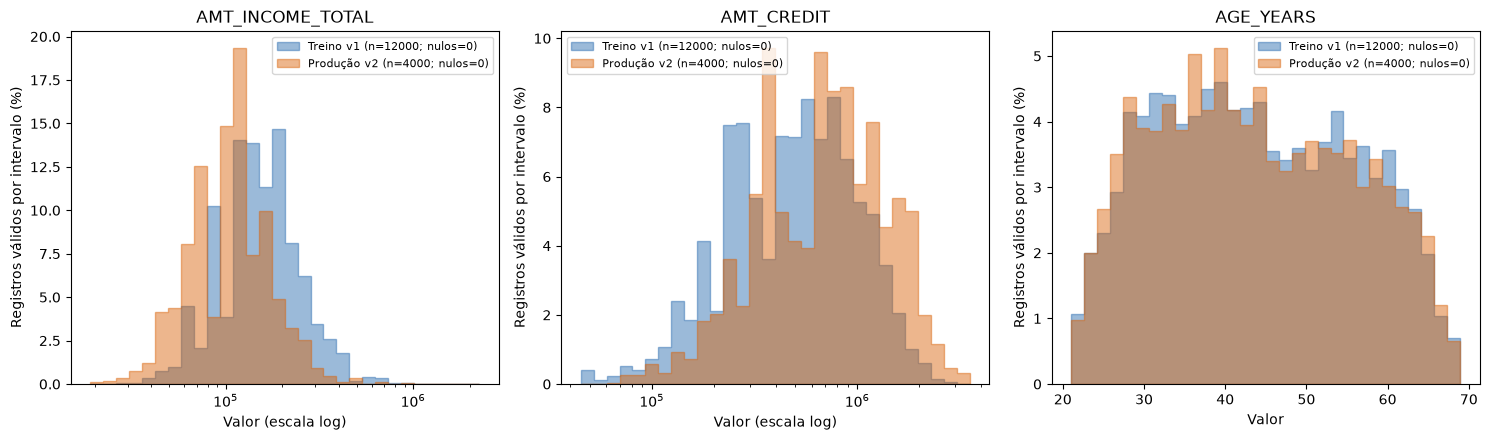

In [6]:
production_ids = partitions["producao"]["SK_ID_CURR"]
production_v1 = version_one.loc[version_one["SK_ID_CURR"].isin(production_ids)].copy()
production_v2 = version_two.loc[version_two["SK_ID_CURR"].isin(production_ids)].copy()
preparation.validate_partitions({**partitions, "producao": production_v1})
preparation.validate_partitions({**partitions, "producao": production_v2})
display(
    validator.summarize(
        {
            "treino_v1": reference,
            "producao_v1": production_v1,
            "producao_v2": production_v2,
        }
    )
)
figures["referencia_producao_v2_histogramas"] = reporter.plot_overlaid_histograms(
    reference,
    production_v2,
    columns=comparison_columns,
    log_columns=log_columns,
    labels=("Treino v1", "Produção v2"),
)

## 5 Confirmar os sinais com Evidently e registrar no MLflow

Aplicamos o monitor existente aos dois lotes de produção com o mesmo modelo
congelado. Nas numéricas, o teste KS sinaliza valor-p menor que 0,01; nas
categóricas e flags, o PSI sinaliza valor a partir de 0,20. O alerta global exige
pelo menos 20% das dez features em drift.

O controle v1 permite avaliar a variação natural frente ao treino. Esperamos
identificar renda e crédito na v2; as outras oito features são controles.
Valor-p pequeno não mede a intensidade da mudança nem seu impacto financeiro.
Os limiares são demonstrativos e múltiplos testes podem produzir falsos alertas.

As métricas, histogramas, hashes dos dois CSVs e relatórios serão vinculados
à execução de treinamento. Os CSVs individuais não serão anexados ao MLflow.


In [7]:
execution_id = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
execution_path = processed_path / "monitoring" / "base_v2" / execution_id
monitor = DriftMonitor(
    numeric_columns=preparation.numeric_features,
    categorical_columns=preparation.categorical_features + preparation.binary_features,
    output_dir=execution_path,
)
tracker = ExperimentTracker(
    "tech-challenge-4-fintech",
    tracking_uri=experiment["tracking_uri"],
    artifact_location=(processed_path / "monitoring/mlartifacts").as_uri(),
)
results = {}
control_auc = None
with tracker.run(
    f"base_v2_{execution_id}",
    parameters={
        **monitor.parameters,
        "income_factor": income_factor,
        "credit_factor": credit_factor,
        "threshold": threshold,
        "version_rows": len(version_two),
    },
    tags={
        "training_run_id": experiment["training_run_id"],
        "model_uri": experiment["model_uri"],
        "v1_sha256": preparation.source_hash(processed_path / "credit_scoring.csv"),
        "v2_sha256": preparation.source_hash(version_two_path),
        "simulation": "paired_feature_shift_target_unchanged",
    },
) as monitoring_run:
    for name, batch in {
        "producao_v1": production_v1,
        "producao_v2": production_v2,
    }.items():
        with tracker.run(name, nested=True):
            result = monitor.evaluate_batch(
                name,
                batch,
                reference,
                predictor,
                preparation.contract,
                target=preparation.target,
                threshold=threshold,
                control_auc=control_auc,
            )
            tracker.log(
                metrics=result["metrics"],
                tags={"status": result["status"]},
                artifacts=result["artifacts"],
            )
            results[name] = result
            if name == "producao_v1":
                control_auc = result["metrics"]["roc_auc"]
    summary = monitor.summarize(results, execution_path / "summary.json")
    for name, figure in figures.items():
        figure.savefig(execution_path / f"{name}.png", dpi=150, bbox_inches="tight")
    tracker.log(
        artifacts=[
            execution_path / "summary.json",
            execution_path / "pipeline.jsonl",
            *[execution_path / f"{name}.png" for name in figures],
        ]
    )

2026/10/10 16:33:09 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/10 16:33:09 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/10 16:33:09 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



In [8]:
for name in results:
    display(Markdown(f"**{name} — resultado por feature**"))
    display(results[name]["drift_table"])
    relative_path = (execution_path / f"{name}.html").relative_to(project_root)
    display(Markdown(f"[Abrir relatório Evidently](../{relative_path})"))
display(
    summary[
        [
            "input_rows",
            "quality_passed",
            "drifted_features",
            "drift_alert",
            "roc_auc",
            "recall",
            "auc_drop",
            "performance_alert",
        ]
    ]
)
print(f"Execução MLflow: {monitoring_run.info.run_id}")

**producao_v1 — resultado por feature**

,feature,method,score,threshold,drift
0,AGE_YEARS,ks,0.435082,0.01,False
1,AMT_INCOME_TOTAL,ks,0.226054,0.01,False
2,AMT_CREDIT,ks,0.541242,0.01,False
3,AMT_ANNUITY,ks,0.405779,0.01,False
4,CNT_CHILDREN,ks,0.593909,0.01,False
5,NAME_INCOME_TYPE,psi,0.009222,0.20,False
6,NAME_EDUCATION_TYPE,psi,0.000998,0.20,False
7,NAME_HOUSING_TYPE,psi,0.000929,0.20,False
8,FLAG_OWN_CAR,psi,0.000291,0.20,False
9,FLAG_OWN_REALTY,psi,0.001403,0.20,False


[Abrir relatório Evidently](../data/processed/monitoring/base_v2/20261010T163309437338Z/producao_v1.html)

**producao_v2 — resultado por feature**

,feature,method,score,threshold,drift
0,AGE_YEARS,ks,4.350824e-01,0.01,False
1,AMT_INCOME_TOTAL,ks,0.000000e+00,0.01,True
2,AMT_CREDIT,ks,6.947000e-102,0.01,True
3,AMT_ANNUITY,ks,4.057791e-01,0.01,False
4,CNT_CHILDREN,ks,5.939094e-01,0.01,False
5,NAME_INCOME_TYPE,psi,9.222419e-03,0.20,False
6,NAME_EDUCATION_TYPE,psi,9.980977e-04,0.20,False
7,NAME_HOUSING_TYPE,psi,9.286781e-04,0.20,False
8,FLAG_OWN_CAR,psi,2.911016e-04,0.20,False
9,FLAG_OWN_REALTY,psi,1.402804e-03,0.20,False


[Abrir relatório Evidently](../data/processed/monitoring/base_v2/20261010T163309437338Z/producao_v2.html)

,input_rows,quality_passed,drifted_features,drift_alert,roc_auc,recall,auc_drop,performance_alert
producao_v1,4000.0,1.0,0.0,0.0,0.601531,0.603715,NaN,NaN
producao_v2,4000.0,1.0,2.0,1.0,0.602180,0.569659,-0.000649,0.0


Execução MLflow: 71b1b9d17c044b2fb8ed8fa48ea5342d


## 6 Conclusão e limites da demonstração

A evidência deve ser lida em conjunto: deslocamento nos histogramas, variáveis
identificadas pelo teste e impacto medido pelo modelo congelado. Com os fatores
padrão, esperamos duas features em drift na v2, enquanto o lote permanece válido
para o contrato. Confira o resultado efetivo nas tabelas acima.

Os alvos originais foram mantidos apenas para comparação didática: eles não
representam desfechos observados depois da mudança de renda e crédito. Data
Drift pode ocorrer sem queda de AUC; isso não é falha do detector nem demonstra
necessidade automática de retreinamento. Esta v2 não simula Concept Drift.

O próximo passo operacional será definir a resposta aos alertas, obter rótulos
representativos do novo cenário e avaliar um candidato em dados independentes.
O CSV v2 contém também versões alteradas de IDs do treino original; não se deve
usá-lo integralmente como um novo conjunto independente de avaliação.

**Artefatos:** CSV v2 em `data/processed/credit_scoring_v2.csv`; histogramas PNG,
relatórios HTML/JSON e resumo em `data/processed/monitoring/base_v2/<execução>/`,
com as evidências vinculadas ao MLflow. Reexecutar este notebook recria o CSV v2
a partir da v1 e cria uma nova execução de monitoramento.
